In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df=pd.read_csv('ecommerce_clean_data.csv')

In [5]:
df.head()

,OrderID,OrderDate,CustomerID,PaymentMethod,OrderStatus,CustomerName,Gender,Age,City,Region,...,Profit,ProductName,Category,CostPrice,SellingPrice,Year,Month,MonthName,YearMonth,ProfitMarginPct
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,12649.20,Mouse,Electronics,5353.0,10018.0,2026,1,January,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,6532.80,Shampoo,Beauty,3112.0,5568.0,2026,1,January,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3909.45,Table Lamp,Home,5905.0,10331.0,2026,2,February,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,2006.80,Air Fryer,Home,3425.0,4363.0,2026,2,February,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,4543.90,T-Shirt,Fashion,3999.0,6601.0,2025,11,November,2025-11,36.229758


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12558 entries, 0 to 12557
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          12558 non-null  object 
 1   OrderDate        12558 non-null  object 
 2   CustomerID       12558 non-null  object 
 3   PaymentMethod    12558 non-null  object 
 4   OrderStatus      12558 non-null  object 
 5   CustomerName     12558 non-null  object 
 6   Gender           12558 non-null  object 
 7   Age              12558 non-null  int64  
 8   City             12558 non-null  object 
 9   Region           12558 non-null  object 
 10  SignupDate       12558 non-null  object 
 11  orderDetailID    12558 non-null  object 
 12  ProductID        12558 non-null  object 
 13  Quantity         12558 non-null  int64  
 14  UnitPrice        12558 non-null  float64
 15  DiscountPct      12558 non-null  float64
 16  SalesAmount      12558 non-null  float64
 17  Profit      

In [7]:
df.shape

(12558, 27)

In [8]:
df.describe()

,Age,Quantity,UnitPrice,DiscountPct,SalesAmount,Profit,CostPrice,SellingPrice,Year,Month,ProfitMarginPct
count,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000,12558.000000
mean,39.065377,2.501752,6272.299570,10.742156,14010.138708,4804.382457,3680.883023,6272.299570,2024.835165,6.002150,31.293145
std,12.303175,1.119501,3461.536155,7.112802,10628.052040,4894.725391,1846.766235,3461.536155,0.762190,3.287781,13.355564
min,18.000000,1.000000,319.000000,0.000000,239.250000,-2048.000000,232.000000,319.000000,2024.000000,1.000000,-10.940224
25%,28.000000,2.000000,3416.000000,5.000000,5949.000000,1342.400000,2400.000000,3416.000000,2024.000000,3.000000,21.079173
50%,40.000000,2.000000,6288.000000,10.000000,11210.400000,3215.600000,3640.000000,6288.000000,2025.000000,6.000000,32.433378
75%,50.000000,4.000000,8847.000000,15.000000,20044.800000,6608.400000,5353.000000,8847.000000,2025.000000,9.000000,42.278551
max,60.000000,4.000000,14270.000000,25.000000,57080.000000,30860.000000,6882.000000,14270.000000,2026.000000,12.000000,54.342273


## Step _ Business Question 
# Sales Distribution
#Question
## Individual Transaction how is it sales amount distribution

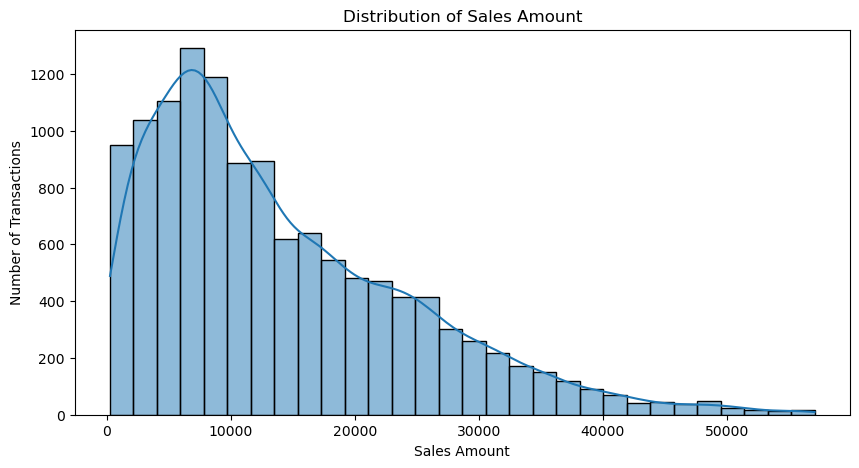

In [13]:
plt.figure(figsize=(10,5))

sns.histplot(
df['SalesAmount'],
    bins=30,
    kde=True
 )

plt.title('Distribution of Sales Amount')
plt.xlabel('Sales Amount')
plt.ylabel('Number of Transactions')
plt.show()

# Profit Distribution

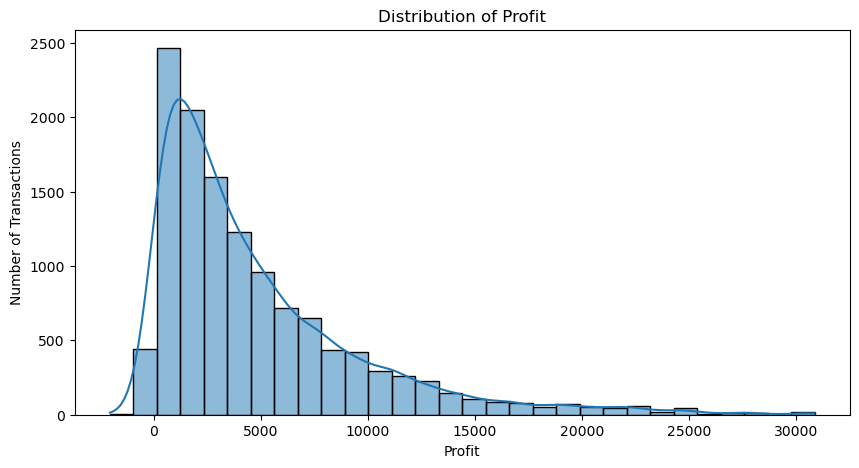

In [14]:
plt.figure(figsize=(10,5))

sns.histplot(
df['Profit'],
    bins=30,
    kde=True
 )

plt.title('Distribution of Profit')
plt.xlabel('Profit')
plt.ylabel('Number of Transactions')
plt.show()

In [15]:
## Step 7 Business Question #2
# Monthly Revenue Trend
# Question:
# Time Time ke saath sales ka behaviour kaise hai?


In [19]:
monthly_sales=(
    df[df["OrderStatus"] == "Delivered"]
    .groupby('YearMonth')["SalesAmount"]
    .sum()
    .reset_index()
)

In [20]:
monthly_sales

,YearMonth,SalesAmount
0,2024-01,4690868.90
1,2024-02,4089338.70
2,2024-03,5296276.35
3,2024-04,4677015.85
4,2024-05,5020831.80
5,2024-06,5343347.60
6,2024-07,6165635.20
7,2024-08,5359728.15
8,2024-09,5302620.35
9,2024-10,4759925.10


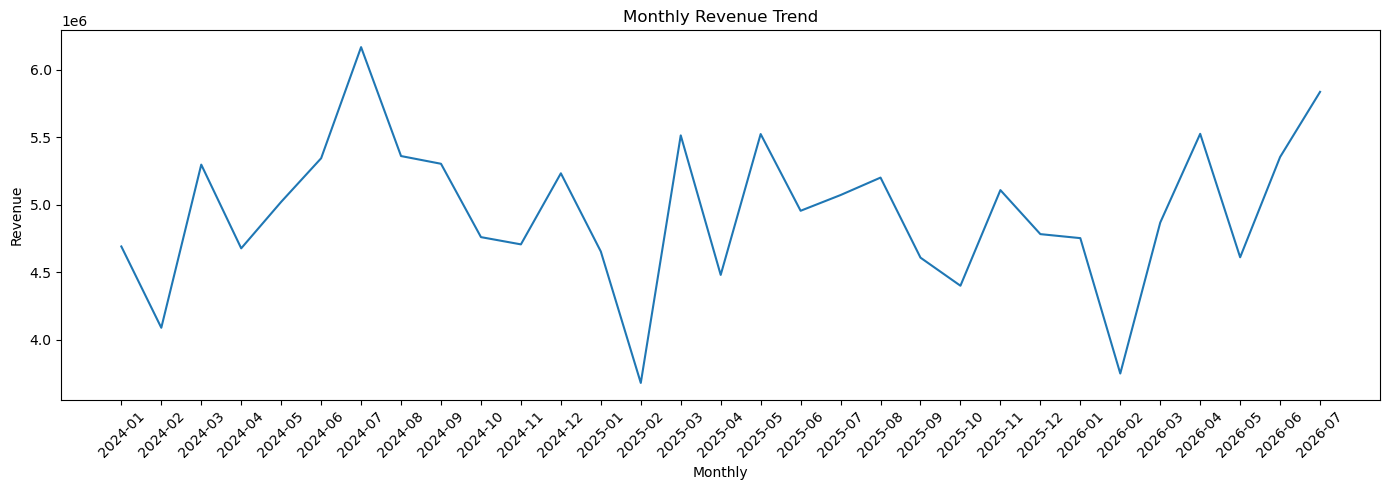

In [26]:
plt.figure(figsize=(14,5))
plt.plot(
    monthly_sales['YearMonth'],
    monthly_sales['SalesAmount']
)
plt.title('Monthly Revenue Trend')
plt.xlabel('Monthly')
plt.ylabel('Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
monthly_profit=(
    df[df["OrderStatus"]=="Delivered"]
    .groupby("YearMonth")['Profit']
    .sum()
    .reset_index()
)

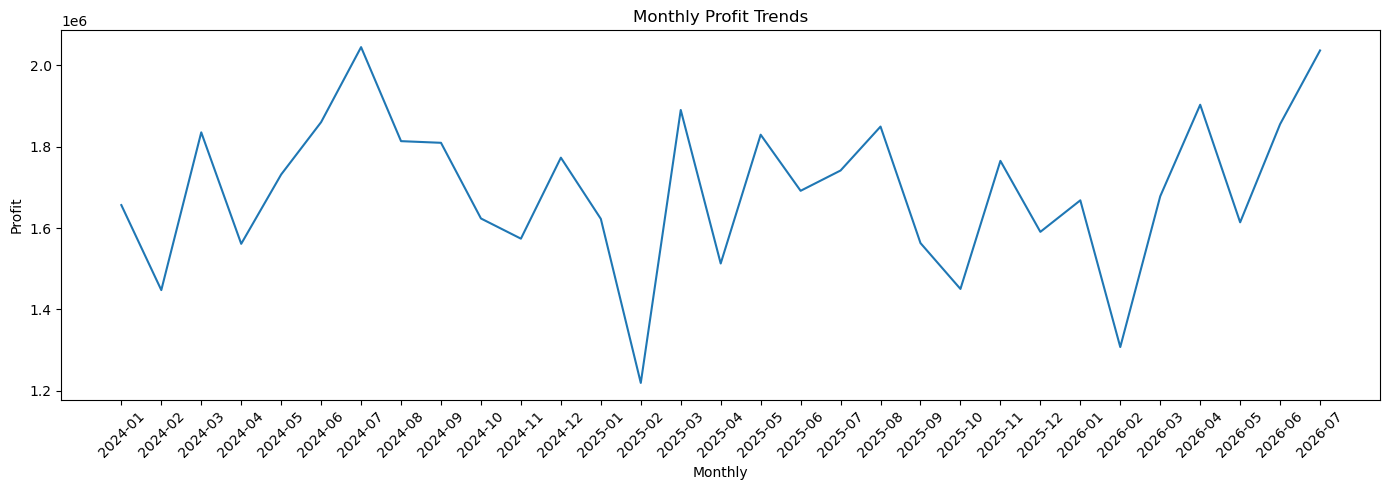

In [33]:
plt.figure(figsize=(14,5))

plt.plot(
monthly_profit['YearMonth'],
monthly_profit['Profit']
    
)
plt.title('Monthly Profit Trends')
plt.xlabel('Monthly')
plt.ylabel('Profit')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
## Step 9 - Business Questions #3
# Category Performance
# Question

# which category is generate high revenue

In [39]:
category_sales=(
    df[df["OrderStatus"]== 'Delivered']
    .groupby('Category')['SalesAmount']
    .sum()
    .sort_values(ascending=False)
)

In [40]:
category_sales

Category
Home           41719144.50
Electronics    39483785.90
Fashion        30509991.50
Beauty         24937008.05
Books          16662009.60
Name: SalesAmount, dtype: float64

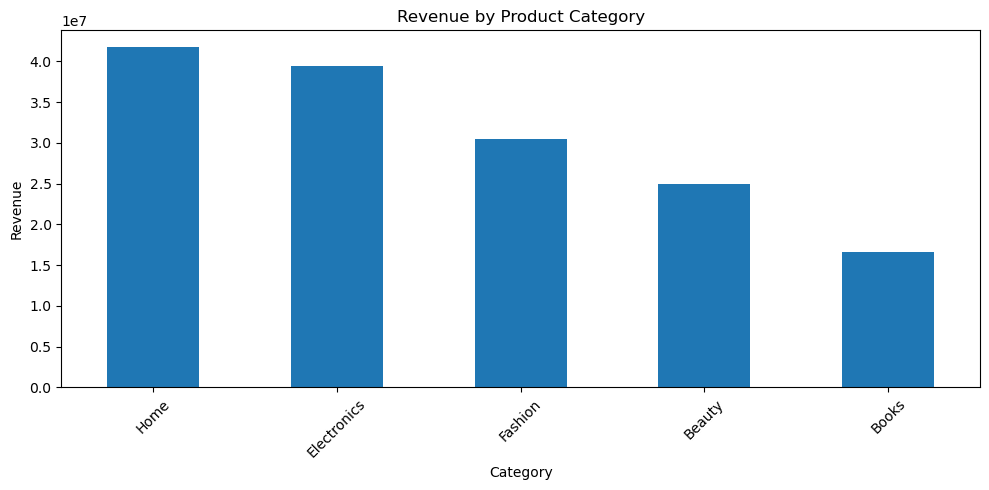

In [47]:
plt.figure(figsize=(10,5))
category_sales.plot(kind="bar")
    
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [49]:
# Category Profit
category_profit=(
    df[df['OrderStatus']=='Delivered']
        .groupby('Category')['Profit']
        .sum()
        .sort_values(ascending=False)
)

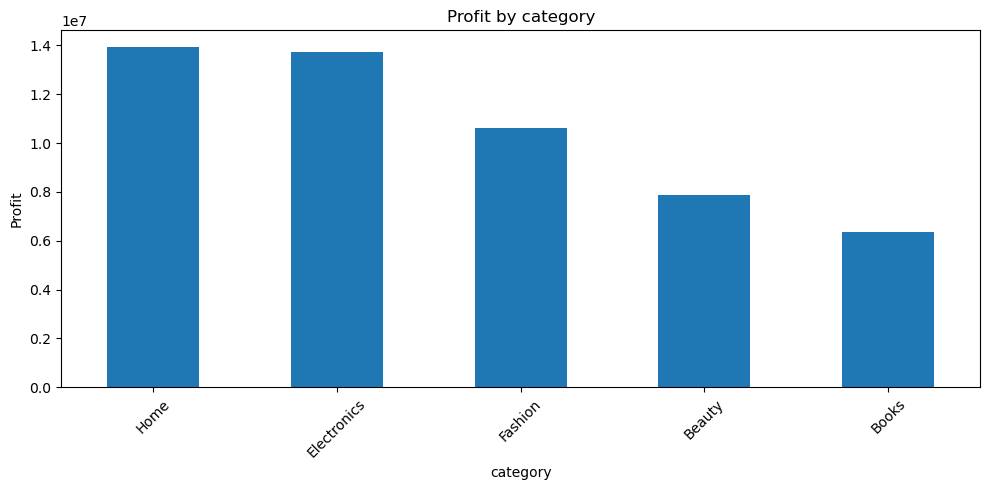

In [56]:
plt.figure(figsize=(10,5))

category_profit.plot(kind='bar')
    
plt.title('Profit by category')
plt.xlabel('category')
plt.ylabel('Profit')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [57]:
# Step 11 - Business Question 
# nRegion Performance
# Question:

# Which region are performing best

In [60]:
region_sales=(
    df[df["OrderStatus"]=='Delivered']
    .groupby('Region')['SalesAmount']
    .sum()
    .sort_values(ascending=False)
)

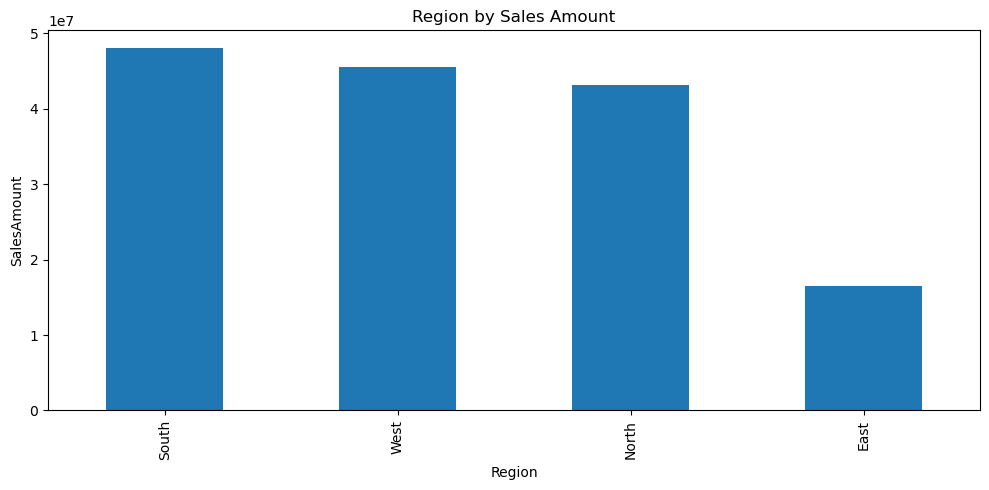

In [64]:
plt.figure(figsize=(10,5))
region_sales.plot(kind="bar")
plt.title("Region by Sales Amount")
plt.xlabel("Region")
plt.ylabel("SalesAmount")
plt.tight_layout()
plt.show()

In [ ]:
## Customers which payment method are using 